In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import data

TNG_H = 0.6774

In [2]:
_tree_data = data.import_tree('data/tree_data')

In [3]:
_tree_data

{'mpeak_pre': array([2.3211329e+14, 3.5674282e+11, 1.3042794e+12, ..., 3.4198965e+11,
        3.2572418e+11, 3.2434274e+11], dtype=float32),
 'stellar_mass': array([1.2425559e+12, 7.6635783e+10, 3.6641698e+10, ..., 8.1088118e+09,
        9.4963722e+09, 7.4886108e+09], dtype=float32),
 'a_1/2': array([0.64516129, 0.42372881, 0.32258065, ..., 0.33333333, 0.30120482,
        0.26809651]),
 'mpeak': array([[5.07998942e-07, 5.07998942e-07, 5.04704668e-06, ...,
         9.88508952e-01, 9.95119996e-01, 1.00000000e+00],
        [5.73086331e-05, 5.73086331e-05, 8.40591303e-04, ...,
         1.00000000e+00, 1.00000000e+00, 1.00000000e+00],
        [3.73714535e-04, 3.73714535e-04, 1.37697147e-03, ...,
         1.00000000e+00, 1.00000000e+00, 1.00000000e+00],
        ...,
        [2.06868012e-03, 2.06868012e-03, 4.80253611e-03, ...,
         9.90724938e-01, 9.97368228e-01, 1.00000000e+00],
        [4.92217046e-04, 4.92217046e-04, 4.08065739e-03, ...,
         9.89657670e-01, 9.89657670e-01, 1.0000

In [4]:
_tree_data['mpeak'].shape

(3240, 100)

In [4]:
len(_tree_data['subfind_id'])

3240

In [5]:
mah = _tree_data.pop('mpeak')

In [7]:
for ii in range(100):
    mahii = mah[:, ii]
    _tree_data[f'mah{ii}'] = mahii
_tree_data

{'mpeak_pre': array([2.3211329e+14, 3.5674282e+11, 1.3042794e+12, ..., 3.4198965e+11,
        3.2572418e+11, 3.2434274e+11], dtype=float32),
 'stellar_mass': array([1.2425559e+12, 7.6635783e+10, 3.6641698e+10, ..., 8.1088118e+09,
        9.4963722e+09, 7.4886108e+09], dtype=float32),
 'a_1/2': array([0.64516129, 0.42372881, 0.32258065, ..., 0.33333333, 0.30120482,
        0.26809651]),
 'subfind_id': array([ 31342,  31346,  31347, ..., 563783, 569305, 571094]),
 'mah0': array([5.07998942e-07, 5.73086331e-05, 3.73714535e-04, ...,
        2.06868012e-03, 4.92217046e-04, 1.19972495e-03]),
 'mah1': array([5.07998942e-07, 5.73086331e-05, 3.73714535e-04, ...,
        2.06868012e-03, 4.92217046e-04, 1.19972495e-03]),
 'mah2': array([5.04704668e-06, 8.40591303e-04, 1.37697147e-03, ...,
        4.80253611e-03, 4.08065739e-03, 1.49267354e-02]),
 'mah3': array([5.79056830e-06, 8.40591303e-04, 2.33138878e-03, ...,
        1.16924388e-02, 8.25506576e-03, 2.28032585e-02]),
 'mah4': array([7.94242016

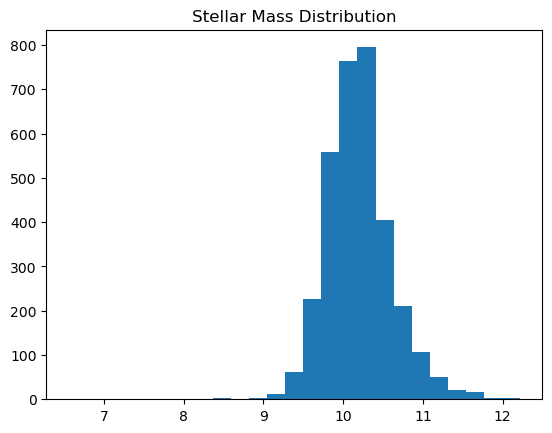

In [8]:
plt.hist(np.log10(_tree_data['stellar_mass']), bins = 25);
plt.title("Stellar Mass Distribution")
plt.show()

In [9]:
# Define mask on stellar mass
mass = np.log10(_tree_data['stellar_mass'])
mask = (mass >= 10)&(mass <= 10.2)
sum(mask)

687

In [10]:
color_data = data.import_color('data/color_data')

In [11]:
color_data

,sdss_u,sdss_g,sdss_r,sdss_i,sdss_z,wfc_acs_f606w,des_y,jwst_f150w,subfind_id
0,-21.400572,-23.256830,-24.071045,-24.477274,-24.844450,-23.948242,-25.025240,-25.319426,0
1,-20.209169,-21.945702,-22.715570,-23.104830,-23.444975,-22.598524,-23.602861,-23.875483,1
2,-20.517130,-22.175474,-22.930420,-23.319283,-23.665720,-22.814957,-23.829544,-24.111971,2
3,-20.308001,-21.670481,-22.270124,-22.612875,-22.929995,-22.174856,-23.081690,-23.360138,3
4,-18.997976,-20.636168,-21.383369,-21.771263,-22.104784,-21.268999,-22.255264,-22.532751,4
...,...,...,...,...,...,...,...,...,...
4371206,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4371206
4371207,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4371207
4371208,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4371208
4371209,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4371209


In [12]:
# Convert dictionary to pandas data frame
tree_data = pd.DataFrame(_tree_data)

# Make cut on mpeak_pre from 11.8 - 12.2
tree_data = tree_data[mask]
tree_data

,mpeak_pre,stellar_mass,a_1/2,subfind_id,mah0,mah1,mah2,mah3,mah4,mah5,...,mah90,mah91,mah92,mah93,mah94,mah95,mah96,mah97,mah98,mah99
12,5.965262e+11,1.464120e+10,0.344828,31366,0.000358,0.000358,0.002042,0.004013,0.007774,0.011182,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0
14,3.646284e+11,1.526207e+10,0.290698,31373,0.000489,0.000489,0.000489,0.000489,0.000724,0.000814,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0
20,3.440633e+11,1.490622e+10,0.184162,31382,0.001441,0.001441,0.004860,0.007152,0.013564,0.019683,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0
21,4.527960e+11,1.518262e+10,0.193050,31387,0.001664,0.001664,0.006482,0.015070,0.021947,0.031313,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0
22,3.976093e+11,1.031032e+10,0.212314,31408,0.000508,0.000508,0.002066,0.007441,0.020711,0.030050,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3193,4.223115e+11,1.233308e+10,0.344828,548993,0.000597,0.000597,0.001561,0.002929,0.005986,0.008713,...,0.968305,0.973938,0.980485,0.982733,0.987789,0.992077,1.000000,1.000000,1.000000,1.0
3197,3.942215e+11,1.034542e+10,0.364964,555077,0.000520,0.000520,0.000520,0.000813,0.002266,0.002987,...,0.951049,0.955168,0.955616,0.961409,0.968342,0.968342,0.979227,0.992816,0.995776,1.0
3205,3.930156e+11,1.272888e+10,0.301205,555635,0.001065,0.001065,0.006738,0.008799,0.012593,0.018167,...,0.967405,0.970312,0.974893,0.981217,0.986403,0.986403,0.998464,1.000000,1.000000,1.0
3229,3.920962e+11,1.462191e+10,0.279330,554105,0.000596,0.000596,0.002253,0.003411,0.007137,0.014277,...,0.986205,0.987247,0.987247,0.987247,0.988049,0.991291,0.991291,0.995378,1.000000,1.0


In [13]:
# Merge tree_data and color_data
bin_data = pd.merge(tree_data, color_data, on='subfind_id')
bin_data

,mpeak_pre,stellar_mass,a_1/2,subfind_id,mah0,mah1,mah2,mah3,mah4,mah5,...,mah98,mah99,sdss_u,sdss_g,sdss_r,sdss_i,sdss_z,wfc_acs_f606w,des_y,jwst_f150w
0,5.965262e+11,1.464120e+10,0.344828,31366,0.000358,0.000358,0.002042,0.004013,0.007774,0.011182,...,1.000000,1.0,-17.742931,-19.414213,-20.161619,-20.539045,-20.856081,-20.048033,-20.998013,-21.260725
1,3.646284e+11,1.526207e+10,0.290698,31373,0.000489,0.000489,0.000489,0.000489,0.000724,0.000814,...,1.000000,1.0,-17.884657,-19.585875,-20.339680,-20.718451,-21.043705,-20.224962,-21.195498,-21.464548
2,3.440633e+11,1.490622e+10,0.184162,31382,0.001441,0.001441,0.004860,0.007152,0.013564,0.019683,...,1.000000,1.0,-17.184124,-19.022631,-19.841457,-20.247831,-20.602690,-19.717890,-20.771837,-21.058262
3,4.527960e+11,1.518262e+10,0.193050,31387,0.001664,0.001664,0.006482,0.015070,0.021947,0.031313,...,1.000000,1.0,-17.185823,-19.032761,-19.854538,-20.264864,-20.622145,-19.730726,-20.788546,-21.074467
4,3.976093e+11,1.031032e+10,0.212314,31408,0.000508,0.000508,0.002066,0.007441,0.020711,0.030050,...,1.000000,1.0,-16.839891,-18.657366,-19.468691,-19.875763,-20.226789,-19.346369,-20.385799,-20.666683
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
682,4.223115e+11,1.233308e+10,0.344828,548993,0.000597,0.000597,0.001561,0.002929,0.005986,0.008713,...,1.000000,1.0,-18.842592,-19.926493,-20.309153,-20.576582,-20.859581,-20.245117,-21.006481,-21.304239
683,3.942215e+11,1.034542e+10,0.364964,555077,0.000520,0.000520,0.000520,0.000813,0.002266,0.002987,...,0.995776,1.0,-18.454697,-19.608919,-20.101038,-20.403711,-20.695951,-20.020620,-20.840225,-21.126831
684,3.930156e+11,1.272888e+10,0.301205,555635,0.001065,0.001065,0.006738,0.008799,0.012593,0.018167,...,1.000000,1.0,-17.923876,-19.534647,-20.202070,-20.545542,-20.846922,-20.097975,-20.992567,-21.243032
685,3.920962e+11,1.462191e+10,0.279330,554105,0.000596,0.000596,0.002253,0.003411,0.007137,0.014277,...,1.000000,1.0,-18.225740,-19.635326,-20.260710,-20.613295,-20.937216,-20.161823,-21.092382,-21.378305


In [15]:
bin_data['g-i'] = bin_data['sdss_g'] - bin_data['sdss_i']

In [20]:
cols = [f'mah{ii}' for ii in range(100)]
bin_data[cols]

,mah0,mah1,mah2,mah3,mah4,mah5,mah6,mah7,mah8,mah9,...,mah90,mah91,mah92,mah93,mah94,mah95,mah96,mah97,mah98,mah99
0,0.000358,0.000358,0.002042,0.004013,0.007774,0.011182,0.012590,0.020950,0.022067,0.022067,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0
1,0.000489,0.000489,0.000489,0.000489,0.000724,0.000814,0.000857,0.001876,0.002373,0.002800,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0
2,0.001441,0.001441,0.004860,0.007152,0.013564,0.019683,0.024316,0.030667,0.039182,0.054740,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0
3,0.001664,0.001664,0.006482,0.015070,0.021947,0.031313,0.041891,0.055909,0.063264,0.085143,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0
4,0.000508,0.000508,0.002066,0.007441,0.020711,0.030050,0.038569,0.052879,0.065855,0.077756,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
682,0.000597,0.000597,0.001561,0.002929,0.005986,0.008713,0.011454,0.016659,0.020582,0.026468,...,0.968305,0.973938,0.980485,0.982733,0.987789,0.992077,1.000000,1.000000,1.000000,1.0
683,0.000520,0.000520,0.000520,0.000813,0.002266,0.002987,0.003469,0.003659,0.004428,0.005012,...,0.951049,0.955168,0.955616,0.961409,0.968342,0.968342,0.979227,0.992816,0.995776,1.0
684,0.001065,0.001065,0.006738,0.008799,0.012593,0.018167,0.024011,0.028867,0.034453,0.038151,...,0.967405,0.970312,0.974893,0.981217,0.986403,0.986403,0.998464,1.000000,1.000000,1.0
685,0.000596,0.000596,0.002253,0.003411,0.007137,0.014277,0.016223,0.022204,0.030478,0.036651,...,0.986205,0.987247,0.987247,0.987247,0.988049,0.991291,0.991291,0.995378,1.000000,1.0


In [25]:
bin_data

,mpeak_pre,stellar_mass,a_1/2,subfind_id,mah0,mah1,mah2,mah3,mah4,mah5,...,mah99,sdss_u,sdss_g,sdss_r,sdss_i,sdss_z,wfc_acs_f606w,des_y,jwst_f150w,g-i
0,5.965262e+11,1.464120e+10,0.344828,31366,0.000358,0.000358,0.002042,0.004013,0.007774,0.011182,...,1.0,-17.742931,-19.414213,-20.161619,-20.539045,-20.856081,-20.048033,-20.998013,-21.260725,1.124832
1,3.646284e+11,1.526207e+10,0.290698,31373,0.000489,0.000489,0.000489,0.000489,0.000724,0.000814,...,1.0,-17.884657,-19.585875,-20.339680,-20.718451,-21.043705,-20.224962,-21.195498,-21.464548,1.132576
2,3.440633e+11,1.490622e+10,0.184162,31382,0.001441,0.001441,0.004860,0.007152,0.013564,0.019683,...,1.0,-17.184124,-19.022631,-19.841457,-20.247831,-20.602690,-19.717890,-20.771837,-21.058262,1.225201
3,4.527960e+11,1.518262e+10,0.193050,31387,0.001664,0.001664,0.006482,0.015070,0.021947,0.031313,...,1.0,-17.185823,-19.032761,-19.854538,-20.264864,-20.622145,-19.730726,-20.788546,-21.074467,1.232103
4,3.976093e+11,1.031032e+10,0.212314,31408,0.000508,0.000508,0.002066,0.007441,0.020711,0.030050,...,1.0,-16.839891,-18.657366,-19.468691,-19.875763,-20.226789,-19.346369,-20.385799,-20.666683,1.218397
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
682,4.223115e+11,1.233308e+10,0.344828,548993,0.000597,0.000597,0.001561,0.002929,0.005986,0.008713,...,1.0,-18.842592,-19.926493,-20.309153,-20.576582,-20.859581,-20.245117,-21.006481,-21.304239,0.650089
683,3.942215e+11,1.034542e+10,0.364964,555077,0.000520,0.000520,0.000520,0.000813,0.002266,0.002987,...,1.0,-18.454697,-19.608919,-20.101038,-20.403711,-20.695951,-20.020620,-20.840225,-21.126831,0.794792
684,3.930156e+11,1.272888e+10,0.301205,555635,0.001065,0.001065,0.006738,0.008799,0.012593,0.018167,...,1.0,-17.923876,-19.534647,-20.202070,-20.545542,-20.846922,-20.097975,-20.992567,-21.243032,1.010895
685,3.920962e+11,1.462191e+10,0.279330,554105,0.000596,0.000596,0.002253,0.003411,0.007137,0.014277,...,1.0,-18.225740,-19.635326,-20.260710,-20.613295,-20.937216,-20.161823,-21.092382,-21.378305,0.977968


In [27]:
target = bin_data['g-i'].to_numpy()
target = target.reshape(-1, 1)

cols = [f'mah{ii}' for ii in range(100)]

x = bin_data[cols].to_numpy()
x.shape, target.shape

((687, 100), (687, 1))

In [30]:
from multicam.models import MultiCAM
n_features = 100
n_targets = 1
model = MultiCAM(n_features, n_targets)

In [31]:
model.fit(x, target)

In [32]:
pred = model.predict(x)

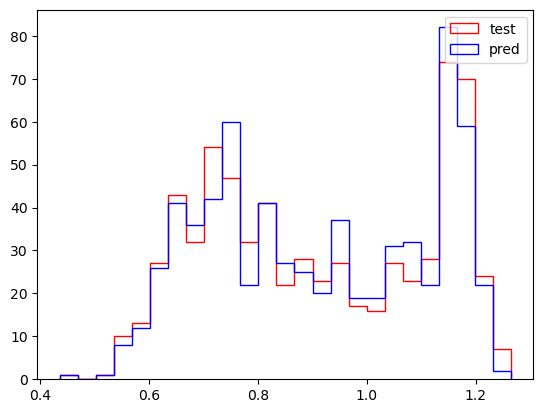

In [33]:
_, bins, _ = plt.hist(target, label='test', histtype='step', bins=25, color='r')
plt.hist(pred, label='pred', histtype='step', bins=bins, color='b')
plt.legend()
plt.show()

In [34]:
# Compute Spearman
from scipy import stats
res = stats.spearmanr(target, pred)
print('Spearman coefficent = ', res)

Spearman coefficent =  SignificanceResult(statistic=0.700001484136602, pvalue=3.0224639300232655e-102)
